# День 08. Упражнение 03
# Переобучение

## 0. Импорты

In [54]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score
import joblib

## 1. Предобработка

1. Прочитай файл `dayofweek.csv` в DataFrame.
2. Используя `train_test_split` с параметрами `test_size=0.2`, `random_state=21`, получи `X_train`, `y_train`, `X_test`, `y_test`.
3. С помощью, например, `value_counts()` проверь, похожее ли распределение классов в train и test.
4. Добавь параметр `stratify=` и проверь распределение снова — теперь оно должно быть более-менее одинаковым в обоих наборах данных.

In [40]:
df = pd.read_csv("../ex02/dayofweek.csv")
X = df.drop(columns=["dayofweek"])
y = df["dayofweek"]


In [41]:
l_model = LogisticRegression(random_state=21, fit_intercept=False)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=21
)
l_model.fit(X_train, y_train)
pred = l_model.predict(X_test)
ac = accuracy_score(y_test, pred)
print(ac)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))


0.6538461538461539
dayofweek
3    0.232196
6    0.212908
1    0.164688
5    0.160237
2    0.092730
0    0.077893
4    0.059347
Name: proportion, dtype: float64
dayofweek
3    0.245562
6    0.204142
5    0.162722
1    0.153846
0    0.091716
4    0.071006
2    0.071006
Name: proportion, dtype: float64


In [42]:
#Повторяем обучение со stratisfy
l_model = LogisticRegression(random_state=21, fit_intercept=False)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=21,
    stratify=y
)
l_model.fit(X_train, y_train)
pred = l_model.predict(X_test)
ac = accuracy_score(y_test, pred)
print(ac)
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))


0.6331360946745562
dayofweek
3    0.234421
6    0.211424
1    0.162463
5    0.160979
2    0.088279
0    0.080861
4    0.061573
Name: proportion, dtype: float64
dayofweek
3    0.236686
6    0.210059
1    0.162722
5    0.159763
2    0.088757
0    0.079882
4    0.062130
Name: proportion, dtype: float64


## 2. Базовые модели

1. Обучи те же самые базовые модели из предыдущего упражнения и вычисли accuracy, используя тестовый набор данных со стратификацией.
2. Все ли модели показали похожие значения метрики? Какая из них показала наибольшее отличие по сравнению с предыдущим упражнением? Напиши ответ в markdown-ячейке в конце раздела.

### a. Логистическая регрессия

In [43]:
logmodel = LogisticRegression(random_state=21, fit_intercept=False)
logmodel.fit(X_train, y_train)
day_predict = logmodel.predict(X_test)
ac = accuracy_score(y_test, day_predict)
print(ac)


0.6331360946745562


### b. SVM

In [44]:
svc_model = SVC(kernel='linear', probability=True, random_state=21)
svc_model.fit(X_train, y_train)
y_pred = svc_model.predict(X_test)
ac = accuracy_score(y_test, y_pred)
print(ac)


0.7159763313609467


/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


### c. Дерево решений

In [45]:
tree_model_4 = DecisionTreeClassifier(max_depth=4, random_state=21)
tree_model_4.fit(X_train, y_train)
y_pred = tree_model_4.predict(X_test)
ac_4 = accuracy_score(y_test, y_pred)
print(ac_4)


0.5295857988165681


### d. Случайный лес

In [46]:
ranf_model = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
ranf_model.fit(X_train, y_train)
y_pred = ranf_model.predict(X_test)
ac = accuracy_score(y_test, y_pred)
print(ac)


0.9289940828402367


Нет, значения accuracy различаются.

| Модель | Ex02: обучающие данные | Ex03: тестовые данные |
|---|---:|---:|
| Логистическая регрессия | 64.06% | 63.31% |
| SVC | 70.28% | 71.60% |
| Дерево решений | 55.16% | 52.96% |
| Случайный лес | 100.00% | 92.90% |

Наибольшее отличие у модели «Случайный лес»: 100.00% → 92.90%. Оценка на обучающих данных была выше оценки на новых примерах.

## 3. Кросс-валидация

Можно было бы “поиграть” с параметрами модели, чтобы добиться более высокой точности на тестовом наборе, но так делать не принято. Такая тактика снова приводит к переобучению. Тестовый набор предназначен только для финальной проверки качества модели.

Однако есть другой способ решения этой задачи — кросс-валидация. Он не использует тестовый набор, а создает дополнительное разбиение обучающего набора. Существует несколько способов реализации, но общая идея одна: появляется валидационный набор, который используется для подбора гиперпараметров.

1. Используя `cross_val_score` с параметром `cv=10`, вычисли среднее значение accuracy и стандартное отклонение для каждой модели, использованной ранее (логистическая регрессия с `solver='liblinear'`, SVC, дерево решений, случайный лес).

### a. Логистическая регрессия

In [47]:
#Создаем лог регрессию
lib_model = OneVsRestClassifier(LogisticRegression(random_state=21, fit_intercept=False, solver="liblinear"))

scores = cross_val_score(
    lib_model,
    X_train,
    y_train,
    cv=10,
    scoring="accuracy",
)
print(scores)
print(scores.mean())
print(scores.std())


[0.56296296 0.61481481 0.59259259 0.60740741 0.55555556 0.57777778
 0.61481481 0.53333333 0.58208955 0.57462687]
0.5815975677169707
0.025322132907253592


### b. SVM

In [48]:
svc_model = SVC(kernel='linear', probability=True, random_state=21)

scores = cross_val_score(
    svc_model,
    X_train,
    y_train,
    cv=10,
    scoring="accuracy",
)
print(scores)
print(scores.mean())
print(scores.std())


/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/a1111/Desktop/DSB10_Intro_to_ML_ID_1577653-1/src/venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/a1111/Desktop/DSB10_Intro_t

[0.65925926 0.75555556 0.62222222 0.65185185 0.65185185 0.64444444
 0.72592593 0.62222222 0.61940299 0.63432836]
0.6587064676616916
0.043585708770590564


### c. Дерево решений

In [49]:
tree_model_4 = DecisionTreeClassifier(max_depth=4, random_state=21)

scores = cross_val_score(
    tree_model_4,
    X_train,
    y_train,
    cv=10,
    scoring="accuracy",
)
print(scores)
print(scores.mean())
print(scores.std())


[0.48148148 0.52592593 0.47407407 0.52592593 0.57037037 0.51111111
 0.5037037  0.48888889 0.54477612 0.46268657]
0.5088944168048645
0.031903139495514356


### d. Случайный лес

In [50]:
ranf_model = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)

scores = cross_val_score(
    ranf_model,
    X_train,
    y_train,
    cv=10,
    scoring="accuracy",
)
print(scores)
print(scores.mean())
print(scores.std())


[0.9037037  0.96296296 0.8962963  0.94074074 0.91851852 0.8962963
 0.92592593 0.8962963  0.93283582 0.90298507]
0.9176561636263129
0.02159583796321821


## 4. Оптимизация

1. Выбери лучшую модель и немного поиграй с её параметрами на кросс-валидации, чтобы найти достаточно хорошие параметры или их комбинацию.
2. Вычисли accuracy для финальной модели на тестовом наборе данных.
3. Построй график, отображающий 10 самых важных признаков для этой модели.
4. Сохрани модель с помощью `joblib`.
5. Загрузи модель, сделай предсказания для тестового набора и вычисли accuracy.

0.9289940828402367
[0.9037037  0.96296296 0.8962963  0.94074074 0.91851852 0.8962963
 0.92592593 0.8962963  0.93283582 0.90298507]
0.9176561636263129
0.02159583796321821


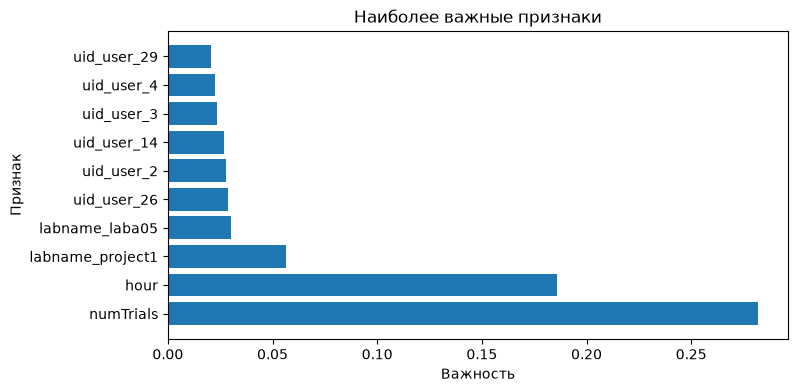

In [53]:
#Лучшая модель - случайный лес
def barh(coefs, names, topn):
    bul_df = pd.DataFrame(abs(coefs), columns=names)
    top = bul_df.sum(axis=0).sort_values(ascending=False)
    top_10 = top.head(topn)
    plt.figure(figsize=(8,4))
    plt.xlabel("Важность")
    plt.ylabel("Признак")
    plt.title("Наиболее важные признаки")
    plt.barh(top_10.index, top_10.values)


ranf_model = RandomForestClassifier(n_estimators=100, max_depth=25, random_state=21)
ranf_model.fit(X_train, y_train)
test_pred = ranf_model.predict(X_test)
test_ac = accuracy_score(y_test, test_pred)
print(test_ac)
scores = cross_val_score(
    ranf_model,
    X_train,
    y_train,
    cv=10,
    scoring="accuracy",
)
print(scores)
print(scores.mean())
print(scores.std())

barh(ranf_model.feature_importances_.reshape(1,-1), X_train.columns, 10)


In [55]:
# Сохраняем обученную модель
joblib.dump(ranf_model, "ranfmodel.joblib")

['ranfmodel.joblib']

In [58]:
load_model = joblib.load("./ranfmodel.joblib")
pred = load_model.predict(X_test)
ac = accuracy_score(y_test, pred)

print(ac)

0.9289940828402367
